# Modelo isotrópico de Liu y Jordan con `pvlib`

Este cuaderno estudia la radiación sobre superficies inclinadas a partir de una serie horaria de GHI. Incluye radiación extraterrestre, índices de claridad mensual, diario y horario, separación de las componentes directa y difusa, modelo horario de Erbs y transposición isotrópica al plano inclinado.

Para mantener el ejemplo reproducible se utiliza GHI de cielo despejado calculada con Ineichen. En un proyecto real, esa columna debe sustituirse por datos medidos o por una fuente meteorológica validada.


## Objetivos

- Calcular la irradiancia extraterrestre normal y horizontal.
- Interpretar los índices de claridad horario, diario y mensual.
- Aplicar las correlaciones diaria y mensual presentadas en clase.
- Separar DNI y DHI mediante el modelo horario de Erbs.
- Transponer las componentes al plano inclinado con el modelo isotrópico.
- Comprobar el balance de las componentes de irradiancia sobre el plano.


## 1. Bibliotecas y modo gráfico


In [ ]:
import importlib.util
from zoneinfo import ZoneInfo

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pvlib
from IPython.display import display
from pvlib import irradiance
from pvlib.location import Location

INTERACTIVO = (
    importlib.util.find_spec("ipympl") is not None
    and importlib.util.find_spec("mplcursors") is not None
)

if INTERACTIVO:
    get_ipython().run_line_magic("matplotlib", "widget")
    import mplcursors
else:
    get_ipython().run_line_magic("matplotlib", "inline")

plt.style.use("seaborn-v0_8-whitegrid")
pd.options.display.float_format = lambda valor: f"{valor:,.3f}"

cursores = []


def activar_cursor(ax, zona_horaria, unidad="W/m²"):
    if not INTERACTIVO:
        return

    cursor = mplcursors.cursor(ax.lines, hover=True)

    @cursor.connect("add")
    def mostrar_valor(seleccion):
        x, y = seleccion.target
        fecha = mdates.num2date(x).astimezone(ZoneInfo(zona_horaria))
        seleccion.annotation.set_text(
            f"{seleccion.artist.get_label()}\n"
            f"{fecha:%Y-%m-%d %H:%M}\n"
            f"{y:.2f} {unidad}"
        )

    cursores.append(cursor)


print("pvlib:", pvlib.__version__)
print("Gráficas interactivas:", INTERACTIVO)


pvlib: 0.16.1
Gráficas interactivas: False


## 2. Sitio y periodo de análisis

Se utiliza Puebla durante todo 2026 con resolución horaria. El límite final se excluye para conservar únicamente registros del año 2026.


In [ ]:
latitude = 19.04
longitude = -98.20
altitude = 2160
timezone = "America/Mexico_City"

sitio = Location(
    latitude=latitude,
    longitude=longitude,
    tz=timezone,
    altitude=altitude,
    name="Puebla",
)

times = pd.date_range(
    start="2026-01-01 00:00",
    end="2027-01-01 00:00",
    freq="1h",
    tz=timezone,
    inclusive="left",
)

print(sitio)
print("Primer registro:", times[0])
print("Último registro:", times[-1])
print("Número de registros:", len(times))


Location: 
  name: Puebla
  latitude: 19.04
  longitude: -98.2
  altitude: 2160
  tz: America/Mexico_City
Primer registro: 2026-01-01 00:00:00-06:00
Último registro: 2026-12-31 23:00:00-06:00
Número de registros: 8760


## 3. Posición solar y GHI de entrada

Ineichen se utiliza únicamente para generar una serie reproducible de cielo despejado. No es el modelo de Liu y Jordan ni el modelo de separación de Erbs.


In [ ]:
solar_pos = sitio.get_solarposition(times)
cielo_claro = sitio.get_clearsky(
    times,
    model="ineichen",
    solar_position=solar_pos,
)

datos = solar_pos.join(cielo_claro)
datos = datos.loc[datos["apparent_elevation"] > 0].copy()

display(datos[["apparent_elevation", "zenith", "azimuth", "ghi"]].head())


,apparent_elevation,zenith,azimuth,ghi
2026-01-01 08:00:00-06:00,10.618,79.448,118.961,144.110
2026-01-01 09:00:00-06:00,22.548,67.483,126.151,400.842
2026-01-01 10:00:00-06:00,33.254,56.766,136.018,623.127
2026-01-01 11:00:00-06:00,41.864,48.151,149.664,785.265
2026-01-01 12:00:00-06:00,47.082,42.930,167.625,874.094


## 4. Radiación extraterrestre e índice de claridad horario

`get_extra_radiation` devuelve la irradiancia extraterrestre normal. Para obtener su componente sobre un plano horizontal se multiplica por el coseno del ángulo cenital.

$$
I_{0h}=I_{0n}\cos(\theta_z)
$$

El índice de claridad horario se define como

$$
k_T=\frac{\mathrm{GHI}}{I_{0h}}.
$$


In [ ]:
datos["dni_extra"] = irradiance.get_extra_radiation(
    datos.index,
    solar_constant=1361,
    method="spencer",
)

cos_zenith = np.clip(
    np.cos(np.radians(datos["zenith"])),
    0,
    None,
)

datos["ghi_extra"] = datos["dni_extra"] * cos_zenith
datos["kt_calculado"] = (
    datos["ghi"] / datos["ghi_extra"]
).clip(lower=0, upper=1)

display(
    datos[["dni_extra", "ghi_extra", "ghi", "kt_calculado"]]
    .dropna()
    .head()
)


,dni_extra,ghi_extra,ghi,kt_calculado
2026-01-01 08:00:00-06:00,"1,408.703",257.969,144.110,0.559
2026-01-01 09:00:00-06:00,"1,408.703",539.484,400.842,0.743
2026-01-01 10:00:00-06:00,"1,408.703",772.060,623.127,0.807
2026-01-01 11:00:00-06:00,"1,408.703",939.852,785.265,0.836
2026-01-01 12:00:00-06:00,"1,408.703","1,031.430",874.094,0.847


## 5. Separación horaria mediante Erbs

El modelo de Erbs estima DNI y DHI a partir de GHI, el ángulo cenital y el día del año. También devuelve el índice de claridad horario `kt`.


In [ ]:
erbs = irradiance.erbs(
    ghi=datos["ghi"],
    zenith=datos["zenith"],
    datetime_or_doy=datos.index,
)

datos = datos.join(
    erbs.rename(columns={
        "dni": "dni_erbs",
        "dhi": "dhi_erbs",
        "kt": "kt_erbs",
    })
)

datos["ghi_reconstruida"] = (
    datos["dni_erbs"] * cos_zenith + datos["dhi_erbs"]
)
datos["error_ghi"] = datos["ghi_reconstruida"] - datos["ghi"]

indice_maximo = datos["ghi"].idxmax()
display(
    datos.loc[
        [indice_maximo],
        [
            "ghi",
            "kt_erbs",
            "dni_erbs",
            "dhi_erbs",
            "ghi_reconstruida",
            "error_ghi",
        ],
    ]
)


,ghi,kt_erbs,dni_erbs,dhi_erbs,ghi_reconstruida,error_ghi
2026-08-02 13:00:00-06:00,"1,158.304",0.877,971.137,191.120,"1,158.304",0.000


## 6. Índice de claridad y fracción difusa diaria

Como la resolución es de una hora, la suma de irradiancias horarias dividida entre 1000 produce irradiación diaria en kWh/m².

Para el ejercicio se utiliza la correlación diaria:

$$
\frac{D}{H}=1.0045+0.04349K_T-3.5227K_T^2+2.6313K_T^3,
\qquad K_T\leq0.75
$$

$$
\frac{D}{H}=0.166,
\qquad K_T>0.75.
$$


In [ ]:
diario = pd.DataFrame(index=datos.resample("D").size().index)
diario["H"] = datos["ghi"].resample("D").sum() / 1000
diario["H0"] = datos["ghi_extra"].resample("D").sum() / 1000
diario["D_erbs"] = datos["dhi_erbs"].resample("D").sum() / 1000

diario["KT"] = (diario["H"] / diario["H0"]).clip(0, 1)
diario["fraccion_difusa"] = np.where(
    diario["KT"] <= 0.75,
    1.0045
    + 0.04349 * diario["KT"]
    - 3.5227 * diario["KT"] ** 2
    + 2.6313 * diario["KT"] ** 3,
    0.166,
)

diario["D_correlacion"] = diario["fraccion_difusa"] * diario["H"]
diario["B_correlacion"] = diario["H"] - diario["D_correlacion"]

display(diario.dropna().head())


,H,H0,D_erbs,KT,fraccion_difusa,D_correlacion,B_correlacion
2026-01-01 00:00:00-06:00,5.841,7.296,1.081,0.801,0.166,0.970,4.871
2026-01-02 00:00:00-06:00,5.848,7.311,1.083,0.800,0.166,0.971,4.877
2026-01-03 00:00:00-06:00,5.856,7.328,1.085,0.799,0.166,0.972,4.884
2026-01-04 00:00:00-06:00,5.865,7.345,1.088,0.798,0.166,0.974,4.891
2026-01-05 00:00:00-06:00,5.875,7.364,1.091,0.798,0.166,0.975,4.900


## 7. Índice de claridad y fracción difusa mensual

Para cada mes se calculan los promedios de irradiación diaria global y extraterrestre. La correlación mensual utilizada es

$$
\frac{\overline D}{\overline H}
=1.390-4.027\overline K_T
+5.531\overline K_T^2
-3.108\overline K_T^3.
$$


In [ ]:
mensual = diario[["H", "H0", "D_erbs"]].resample("MS").mean()
mensual["KT"] = (mensual["H"] / mensual["H0"]).clip(0, 1)
mensual["fraccion_difusa"] = (
    1.390
    - 4.027 * mensual["KT"]
    + 5.531 * mensual["KT"] ** 2
    - 3.108 * mensual["KT"] ** 3
).clip(0, 1)

mensual["D_correlacion"] = mensual["fraccion_difusa"] * mensual["H"]
mensual["B_correlacion"] = mensual["H"] - mensual["D_correlacion"]

mensual.index = mensual.index.strftime("%Y-%m")
display(mensual)


,H,H0,D_erbs,KT,fraccion_difusa,D_correlacion,B_correlacion
2026-01,6.088,7.654,1.135,0.795,0.122,0.744,5.344
2026-02,6.972,8.669,1.288,0.804,0.112,0.781,6.191
2026-03,7.981,9.781,1.447,0.816,0.098,0.783,7.198
2026-04,8.671,10.541,1.572,0.823,0.090,0.782,7.889
2026-05,8.901,10.805,1.601,0.824,0.089,0.788,8.113
2026-06,8.967,10.846,1.594,0.827,0.085,0.761,8.206
2026-07,9.039,10.787,1.587,0.838,0.071,0.637,8.402
2026-08,8.819,10.537,1.563,0.837,0.072,0.634,8.184
2026-09,8.262,9.954,1.483,0.830,0.081,0.666,7.596
2026-10,7.349,8.931,1.315,0.823,0.090,0.659,6.690


## 8. Transposición isotrópica al plano inclinado

Se emplean las componentes horarias estimadas por Erbs. El modelo isotrópico calcula la componente difusa del cielo mediante el factor $(1+\cos\beta)/2$ y la componente reflejada mediante el albedo.


In [ ]:
surface_tilt = 20.0
surface_azimuth = 180.0
albedo = 0.20

poa = irradiance.get_total_irradiance(
    surface_tilt=surface_tilt,
    surface_azimuth=surface_azimuth,
    solar_zenith=datos["zenith"],
    solar_azimuth=datos["azimuth"],
    dni=datos["dni_erbs"],
    ghi=datos["ghi"],
    dhi=datos["dhi_erbs"],
    albedo=albedo,
    model="isotropic",
)

datos = datos.join(poa)
datos["poa_reconstruida"] = (
    datos["poa_direct"]
    + datos["poa_sky_diffuse"]
    + datos["poa_ground_diffuse"]
)
datos["error_poa"] = datos["poa_reconstruida"] - datos["poa_global"]

display(
    datos.loc[
        [indice_maximo],
        [
            "poa_direct",
            "poa_sky_diffuse",
            "poa_ground_diffuse",
            "poa_global",
            "error_poa",
        ],
    ]
)


,poa_direct,poa_sky_diffuse,poa_ground_diffuse,poa_global,error_poa
2026-08-02 13:00:00-06:00,916.745,185.357,6.985,"1,109.088",0.000


## 9. Curvas horarias para un día representativo


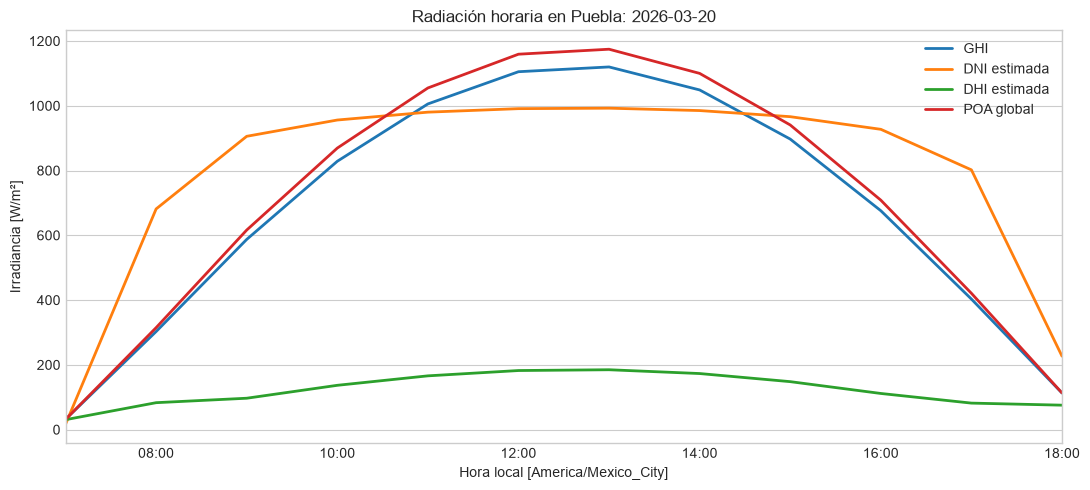

In [ ]:
fecha = "2026-03-20"
dia = datos.loc[fecha]

fig, ax = plt.subplots(figsize=(11, 5))
dia[[
    "ghi",
    "dni_erbs",
    "dhi_erbs",
    "poa_global",
]].plot(ax=ax, linewidth=2)

ax.set_title(f"Radiación horaria en Puebla: {fecha}")
ax.set_xlabel(f"Hora local [{timezone}]")
ax.set_ylabel("Irradiancia [W/m²]")
ax.legend(["GHI", "DNI estimada", "DHI estimada", "POA global"])
activar_cursor(ax, timezone)
fig.tight_layout()
plt.show()


## 10. Comparación de resultados diarios y mensuales


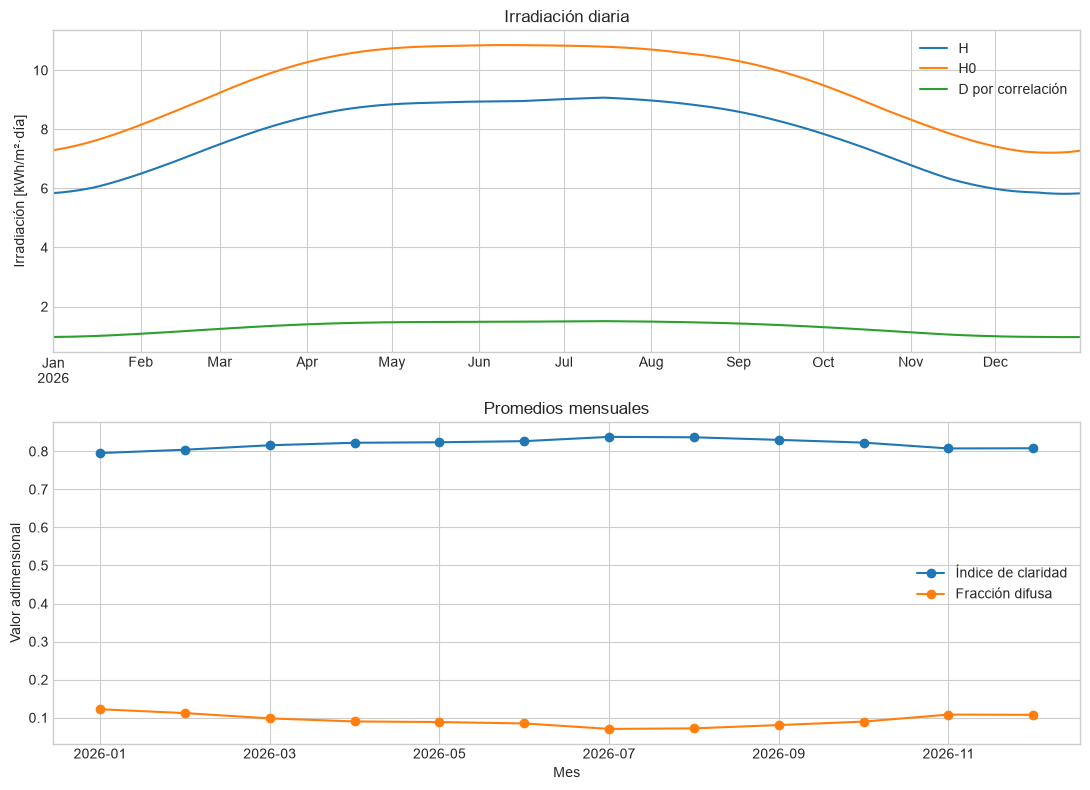

In [ ]:
fig, ejes = plt.subplots(2, 1, figsize=(11, 8))

diario[["H", "H0", "D_correlacion"]].plot(
    ax=ejes[0],
    linewidth=1.5,
)
ejes[0].set_title("Irradiación diaria")
ejes[0].set_ylabel("Irradiación [kWh/m²·día]")
ejes[0].legend(["H", "H0", "D por correlación"])

mensual[["KT", "fraccion_difusa"]].plot(
    ax=ejes[1],
    marker="o",
)
ejes[1].set_title("Promedios mensuales")
ejes[1].set_xlabel("Mes")
ejes[1].set_ylabel("Valor adimensional")
ejes[1].legend(["Índice de claridad", "Fracción difusa"])

fig.tight_layout()
plt.show()


## Interpretación

- `dni_extra` es irradiancia extraterrestre normal; `ghi_extra` es su proyección horizontal.
- `kt_erbs` relaciona GHI con irradiancia extraterrestre horizontal en cada hora.
- Erbs separa la GHI horaria en DNI y DHI.
- Las correlaciones diaria y mensual trabajan con irradiaciones agregadas, no con irradiancias instantáneas.
- `model="isotropic"` transpone las componentes horarias al plano inclinado.
- `poa_global` es la suma de la componente directa, la difusa del cielo y la reflejada por el terreno.

## Actividades breves

1. Cambiar `surface_tilt` a 0°, 20° y 40° y comparar `poa_global`.
2. Cambiar `surface_azimuth` a 90°, 180° y 270° y comparar el perfil horario.
3. Cambiar el albedo de 0.20 a 0.60 e identificar la componente afectada.
4. Sustituir la GHI de Ineichen por una serie medida y repetir la separación con Erbs.
